In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

df = pd.read_csv('../data/student_dropout_risk_2026.csv')

df.head()
# df.shape
# df.info()

,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,...,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,...,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,...,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,...,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,...,4,7.4,1,0,7,0,10,24,5.8,0


In [2]:
df.isna().sum()
df.duplicated().sum()
df["person_id"].duplicated().sum()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   person_id                     100000 non-null  int64  
 1   age                           100000 non-null  int64  
 2   gender                        100000 non-null  str    
 3   nationality                   100000 non-null  str    
 4   first_generation              100000 non-null  int64  
 5   disability_status             100000 non-null  int64  
 6   family_income_level           100000 non-null  str    
 7   scholarship_holder            100000 non-null  int64  
 8   tuition_up_to_date            100000 non-null  int64  
 9   part_time_job                 100000 non-null  int64  
 10  weekly_work_hours             100000 non-null  int64  
 11  course_type                   100000 non-null  str    
 12  study_mode                    100000 non-null  str    
 

,person_id,age,first_generation,disability_status,scholarship_holder,tuition_up_to_date,part_time_job,weekly_work_hours,semester,international_student,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,21.520840,0.420130,0.208770,0.589700,0.784860,0.481920,8.744620,3.617970,0.18094,...,4.366800,7.272294,0.594790,2.372140,6.448120,0.315560,6.318820,23.261360,6.556512,0.320040
std,28867.657797,3.399468,0.493582,0.406432,0.491891,0.410921,0.499676,10.232842,2.112763,0.38497,...,3.651653,3.936264,0.490935,2.587122,2.154185,0.464741,2.079066,23.932468,1.204067,0.466494
min,1.000000,15.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.00000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,4.000000,0.000000
25%,25000.750000,19.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,2.000000,0.00000,...,2.000000,4.500000,0.000000,0.000000,5.000000,0.000000,5.000000,6.000000,5.700000,0.000000
50%,50000.500000,21.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,3.000000,0.00000,...,3.000000,7.100000,1.000000,2.000000,7.000000,0.000000,6.000000,16.000000,6.500000,0.000000
75%,75000.250000,24.000000,1.000000,0.000000,1.000000,1.000000,1.000000,18.000000,5.000000,0.00000,...,6.000000,9.800000,1.000000,3.000000,8.000000,1.000000,8.000000,33.000000,7.400000,1.000000
max,100000.000000,30.000000,1.000000,1.000000,1.000000,1.000000,1.000000,40.000000,8.000000,1.00000,...,30.000000,29.600000,1.000000,20.000000,10.000000,1.000000,10.000000,120.000000,10.000000,1.000000


In [3]:
# df["gender"].value_counts()
# df["family_income_level"].value_counts()
# df["semester"].value_counts()

df[["age", "attendance_rate", "sleep_hours", "stress_level", "satisfaction_score"]].describe() 

,age,attendance_rate,sleep_hours,stress_level,satisfaction_score
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,21.520840,75.102136,6.556512,6.448120,6.318820
std,3.399468,17.425800,1.204067,2.154185,2.079066
min,15.000000,0.000000,4.000000,1.000000,1.000000
25%,19.000000,63.100000,5.700000,5.000000,5.000000
50%,21.000000,76.100000,6.500000,7.000000,6.000000
75%,24.000000,89.000000,7.400000,8.000000,8.000000
max,30.000000,100.000000,10.000000,10.000000,10.000000


In [4]:
dropout_counts = df["dropout"].value_counts()
dropout_percentage = df["dropout"].value_counts(normalize=True) * 100
print(dropout_counts)
print(dropout_percentage)

dropout
0    67996
1    32004
Name: count, dtype: int64
dropout
0    67.996
1    32.004
Name: proportion, dtype: float64


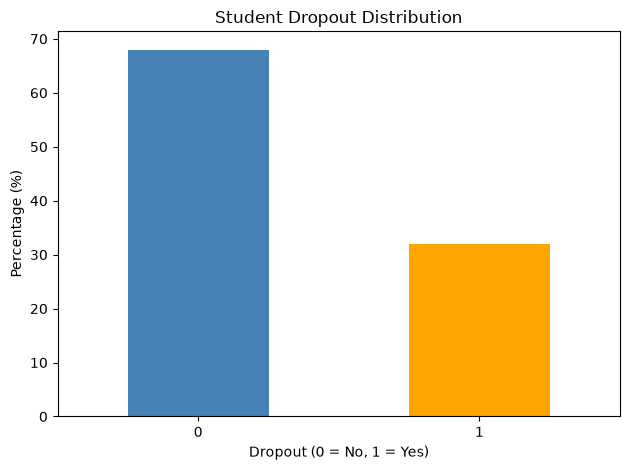

In [5]:
dropout_percentage.plot(
    kind="bar",
    color=["steelblue", "orange"]
)

plt.title("Student Dropout Distribution")
plt.xlabel("Dropout (0 = No, 1 = Yes)")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
df.groupby("dropout")[
    [
        "age",
        "attendance_rate",
        "assignments_submitted_rate",
        "gpa_semester_1",
        "gpa_semester_2",
        "units_passed",
        "units_failed",
        "missed_deadlines",
        "weekly_work_hours",
        "sleep_hours",
        "stress_level"
    ]
].mean().round(2)

,age,attendance_rate,assignments_submitted_rate,gpa_semester_1,gpa_semester_2,units_passed,units_failed,missed_deadlines,weekly_work_hours,sleep_hours,stress_level
dropout,,,,,,,,,,,
0,21.52,78.50,75.18,2.88,2.24,10.98,2.01,1.87,7.47,6.60,6.26
1,21.53,67.87,63.44,1.91,1.44,8.94,4.22,3.44,11.45,6.46,6.86


In [7]:
numeric_df = df.select_dtypes(include=np.number)
correlations = numeric_df.corr()["dropout"].drop("dropout")
correlations = correlations.sort_values()
print(correlations)

gpa_semester_1                 -0.568820
gpa_semester_2                 -0.521448
attendance_rate                -0.284607
assignments_submitted_rate     -0.275410
units_passed                   -0.261394
library_visits_per_month       -0.224356
lms_logins_per_week            -0.201643
tuition_up_to_date             -0.137130
admission_grade                -0.128051
satisfaction_score             -0.085987
extracurricular_activities     -0.075657
sleep_hours                    -0.056373
previous_qualification_grade   -0.032169
semester                       -0.030688
scholarship_holder             -0.022259
person_id                       0.000896
international_student           0.000958
age                             0.001627
commute_time_mins               0.007808
units_enrolled                  0.020710
mental_health_support           0.024438
disability_status               0.049923
first_generation                0.098986
stress_level                    0.130514
part_time_job   

In [9]:
study_mode_dropout = df.groupby("study_mode")["dropout"].mean().mul(100).sort_values(ascending=False)
course_type_dropout = df.groupby("course_type")["dropout"].mean().mul(100).round(2)
family_income_level_dropout = df.groupby("family_income_level")["dropout"].mean().mul(100).round(2)
gender_dropout = df.groupby("gender")["dropout"].mean().mul(100).round(2)

print(study_mode_dropout.round(2))
print(course_type_dropout.round(2))
print(family_income_level_dropout.round(2))
print(gender_dropout.round(2))


study_mode
Part-time    33.67
Full-time    32.00
Online       29.21
Name: dropout, dtype: float64
course_type
Arts & Humanities        32.10
Business                 31.85
Health Sciences          32.11
Law & Social Sciences    31.69
STEM                     32.15
Name: dropout, dtype: float64
family_income_level
High      19.99
Low       42.92
Middle    30.02
Name: dropout, dtype: float64
gender
Female    31.95
Male      32.00
Other     33.45
Name: dropout, dtype: float64


In [10]:
gpa_change = df["gpa_semester_2"].to_numpy() - df["gpa_semester_1"].to_numpy()
print("Average GPA change: ", np.mean(gpa_change).round(3))
print("Median GPA change: ", np.median(gpa_change).round(3))

df["gpa_change"] = (
    df["gpa_semester_2"] - df["gpa_semester_1"]
)

print(
    df.groupby("dropout")["gpa_change"]
      .agg(["mean", "median"])
      .round(3)
)


Average GPA change:  -0.587
Median GPA change:  -0.59
          mean  median
dropout               
0       -0.638   -0.64
1       -0.479   -0.48


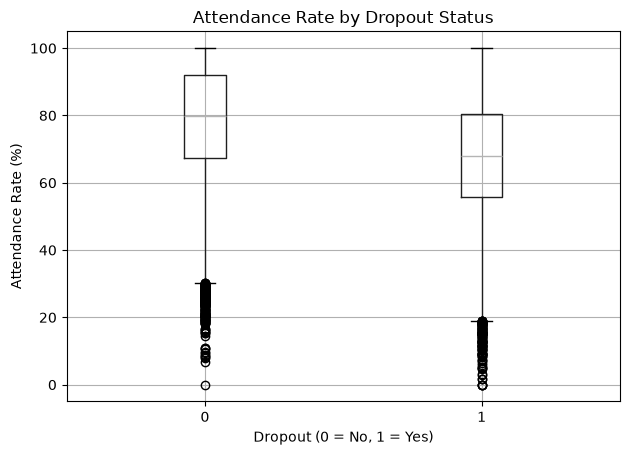

In [11]:
df.boxplot(
    column="attendance_rate",
    by="dropout"
)

plt.title("Attendance Rate by Dropout Status")
plt.suptitle("")
plt.xlabel("Dropout (0 = No, 1 = Yes)")
plt.ylabel("Attendance Rate (%)")
plt.tight_layout()
plt.show()